In [ ]:
import numpy  as np
import matplotlib.pyplot as plt
import sklearn as sk
import tensorflow as tf
import tensorflow_datasets as tfds
import tensorflow.keras as keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,MaxPooling2D,Flatten,Conv2D
from tensorflow.keras.optimizers import SGD,Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy



In [ ]:
# Define the Hyperparameters

In [ ]:
BUFFER_SIZE=70_000
BATCH_SIZE=128
EpOCHS=20

In [ ]:
# Load dataset&Preprocessing

In [ ]:
mnist_dataset,mnist_info=tfds.load(name='mnist',with_info=True,as_supervised=True)
mnist_train,mnist_test= mnist_dataset['train'],mnist_dataset['test']

In [ ]:
mnist_train

<_PrefetchDataset element_spec=(TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

In [ ]:
def scal(image,label):
    image=tf.cast(image,tf.float32)
    image/=255.
    return image,label

In [ ]:
mnist_train=mnist_train.map(scal)
mnist_test=mnist_test.map(scal)

In [ ]:
num_validation_samples=0.1*mnist_info.splits['train'].num_examples
num_validation_samples=tf.cast(num_validation_samples,tf.int64)


In [ ]:
num_test_samples=mnist_info.splits['test'].num_examples
num_test_samples=tf.cast(num_test_samples,tf.int64)

In [ ]:
mnist_train=mnist_train.shuffle(BUFFER_SIZE)

In [ ]:
train_data=mnist_train.skip(num_validation_samples)
validation_data=mnist_train.take(num_validation_samples)

In [ ]:
train_data=train_data.batch(BATCH_SIZE)
validation_data=validation_data.batch(num_validation_samples)
test_data=mnist_test.batch(num_test_samples)

In [ ]:
# Build the model

In [ ]:
erly_stop=keras.callbacks.EarlyStopping(monitor='val_loss',
                                        patience=2,
                                        mode='auto',
                                        min_delta=0,
                                        verbose=1,
                                        restore_best_weights=True
                                        )

In [ ]:
def train_test_model () :
  model=Sequential([
      Conv2D(32,(5,5),activation='relu',input_shape=(28,28,1)),
      MaxPooling2D((2,2)),
      Conv2D(64,(3,3),activation='relu'),
      MaxPooling2D((2,2)),
      Flatten(),
      Dense(10),
  ])

  loss=SparseCategoricalCrossentropy(from_logits=True)
  model.compile(optimizer='adam',loss=loss,metrics=['accuracy'])
  model.fit(train_data,
          epochs=EpOCHS,
          validation_data=validation_data,
          callbacks=[erly_stop],
          verbose=2
          )
  test_loss,test_accuracy=model.evaluate(test_data)

  return model,test_loss,test_accuracy






In [ ]:
model.summary(line_length=100)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                          │ (None, 24, 24, 32)              │               832 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d_8 (MaxPooling2D)             │ (None, 12, 12, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_9 (Conv2D)                          │ (None, 10, 10, 64)              │            18,496 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d_9 (MaxPooling2D)             │ (None, 5, 5, 64)                │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ flatten_4 (Flatten)                        │ (None, 1600)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dense_4 (Dense)                            │ (None, 10)                      │            16,010 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 35,338 (138.04 KB)

 Trainable params: 35,338 (138.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
for images, labels in test_data.take(1):
    images_test = images.numpy()
    labels_test = labels.numpy()

images_plot = np.squeeze(images_test)

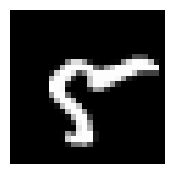

Label: 5


In [ ]:
num_image = 502


plt.figure(figsize=(2, 2))
plt.axis('off')
plt.imshow(images_plot[num_image-1], cmap="gray", aspect='auto')
plt.show()

print("Label: {}".format(labels_test[num_image-1]))

In [ ]:
model=train_test_model()[0]

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


422/422 - 13s - 31ms/step - accuracy: 0.9217 - loss: 0.2723 - val_accuracy: 0.9690 - val_loss: 0.1071
Epoch 2/20
422/422 - 5s - 13ms/step - accuracy: 0.9773 - loss: 0.0751 - val_accuracy: 0.9803 - val_loss: 0.0622
Epoch 3/20
422/422 - 6s - 14ms/step - accuracy: 0.9837 - loss: 0.0549 - val_accuracy: 0.9868 - val_loss: 0.0416
Epoch 4/20
422/422 - 10s - 24ms/step - accuracy: 0.9866 - loss: 0.0445 - val_accuracy: 0.9843 - val_loss: 0.0432
Epoch 5/20
422/422 - 7s - 16ms/step - accuracy: 0.9890 - loss: 0.0364 - val_accuracy: 0.9930 - val_loss: 0.0279
Epoch 6/20
422/422 - 10s - 23ms/step - accuracy: 0.9899 - loss: 0.0320 - val_accuracy: 0.9903 - val_loss: 0.0290
Epoch 7/20
422/422 - 5s - 13ms/step - accuracy: 0.9918 - loss: 0.0273 - val_accuracy: 0.9935 - val_loss: 0.0194
Epoch 8/20
422/422 - 10s - 24ms/step - accuracy: 0.9922 - loss: 0.0245 - val_accuracy: 0.9935 - val_loss: 0.0222
Epoch 9/20
422/422 - 7s - 16ms/step - accuracy: 0.9933 - loss: 0.0217 - val_accuracy: 0.9952 - val_loss: 0.0166

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step


<BarContainer object of 10 artists>

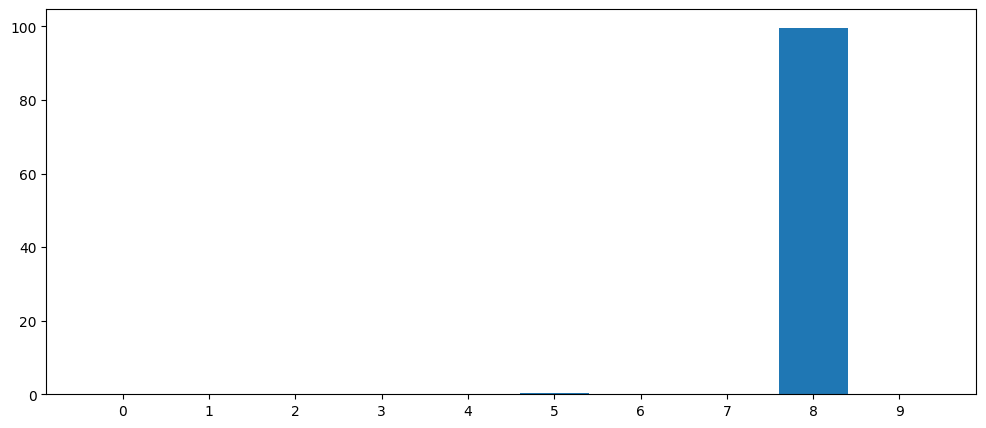

In [ ]:
predictions = model.predict(images_test[num_image-1:num_image])

probabilities = tf.nn.softmax(predictions).numpy()

probabilities = probabilities*100
num_classes = len(probabilities[0])

plt.figure(figsize=(12,5))
plt.bar(
    x=range(num_classes),
    height=probabilities[0],
    tick_label=range(num_classes)
)